In [1]:
import numpy as np
from toolbox import (
    Masking,
    combined_frequency_roc_analysis,
    compute_ROC,
    find_all_indices,
    hot_coding,
)
from toolbox.loading import load_data

In [2]:
IIVV = np.loadtxt("source/IIVV_patterns.txt", dtype=int)
mask = Masking(IIVV)

In [3]:
(
    py_idx,
    patient_no,
    patient_sample,
    Zdata,
    Avg_Cutpats,
    LesionAssessment,
    labels_healthy_vs_cancer,
    labels_cancer_vs_hbd,
    labels_WHO,
) = load_data(path="data", Cutpats_threshold=60, norm="freq")


	Info:	np.abs(Zdata)

Remaining data samples: 244 
	Info:	Select only data Avg_Cutpats <60%

Remaining data samples: 229 

	Info:	z-score Zdata
before: 434.20845093924504 699.3585400487347
Normalized along the frequency axis.

after: -4.3347838749237164e-17 1.000000000000001

	Info:	np.nan_to_num(Zdata)

Remaining data samples: 229 


**Select classification basis task `class_task`**

- `"healthy_vs_cancer"`
- `"cancer_vs_hbd"`
- `"WHO"`

In [4]:
class_task = "healthy_vs_cancer"
# class_task = "cancer_vs_hbd"
# class_task = "WHO"

In [11]:
if class_task == "healthy_vs_cancer":
    print("Healthy vs. cancer\n")
    select_idx = find_all_indices(
        labels_healthy_vs_cancer, ["Healthy", "Cancer"], split=False
    )
    labels = labels_healthy_vs_cancer[select_idx]

elif class_task == "cancer_vs_hbd":
    print("\nHealthy vs. HDB\n")
    select_idx = find_all_indices(
        labels_cancer_vs_hbd, ["Non-cancer", "Cancer"], split=False
    )
    labels = labels_cancer_vs_hbd[select_idx]
elif class_task == "WHO":
    print("\nWHO\n")
    select_idx = find_all_indices(
        labels_WHO,
        ["Healthy", "Cancer", "Mild dysplasia", "Severe dysplasia", "Benign"],
        split=False,
    )
    labels = labels_WHO[select_idx]
Case = patient_no[select_idx]
X = Zdata[select_idx, ...]
Y = hot_coding(labels)

Healthy vs. cancer

Healthy: 89 entries
Cancer: 92 entries
Available cases: ['Cancer' 'Healthy']
Coding: -> forward
{np.str_('Cancer'): [1, 0], np.str_('Healthy'): [0, 1]}


In [6]:
print(X.shape, Y.shape, labels.shape)

(181, 31, 7728) (181, 2) (181,)


NaN are replaced by 0.
(144, 239568) (37, 239568) (144, 2) (37, 2)
Note: Using random sample splitting (not patient-based)


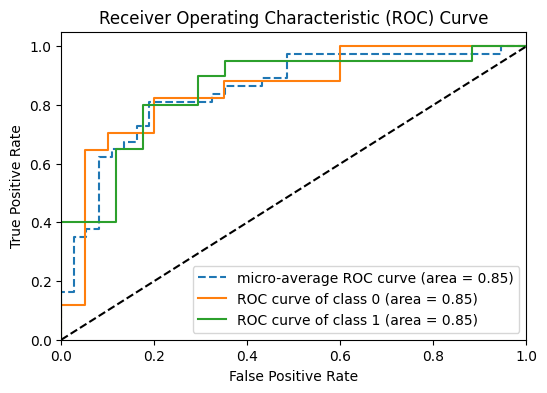

avg_roc_auc=np.float64(0.8529411764705882)


(np.float64(0.8529411764705882),
 {'roc_auc_0': np.float64(0.8529411764705883),
  'roc_auc_1': np.float64(0.8529411764705881)})

In [7]:
compute_ROC(X[:, :, :], Y, test_size=0.2, plot=True)

## Frequency sweep with ranked frequencies from PCA

**1. All IIVV patterns (baseline)**

Performing 15-fold cross-validation with PCA-based frequency ranking and ROC analysis...
Fold 1: 91.7% train / 8.3% test
Fold 1: 91.7% train / 8.3% test
  Training: 166 samples from 88 patients
  Testing:  15 samples from 6 patients
Fold 1 frequency ranking (top 10): [30 27  0 29 12 13 28 16 26  8]
Fold 2: 93.9% train / 6.1% test
Fold 2: 93.9% train / 6.1% test
  Training: 170 samples from 88 patients
  Testing:  11 samples from 6 patients
Fold 2 frequency ranking (top 10): [30 27  0 29 12 13 28 16  8 20]
Fold 3: 93.9% train / 6.1% test
Fold 3: 93.9% train / 6.1% test
  Training: 170 samples from 88 patients
  Testing:  11 samples from 6 patients
Fold 3 frequency ranking (top 10): [30 27  0 29 12 28 13 16 20 11]
Fold 4: 93.9% train / 6.1% test
Fold 4: 93.9% train / 6.1% test
  Training: 170 samples from 88 patients
  Testing:  11 samples from 6 patients
Fold 4 frequency ranking (top 10): [30 27  0 29 12 28  8 10  7 26]
Fold 5: 93.9% train / 6.1% test
Fold 5: 93.9% train / 6.1% test
  T

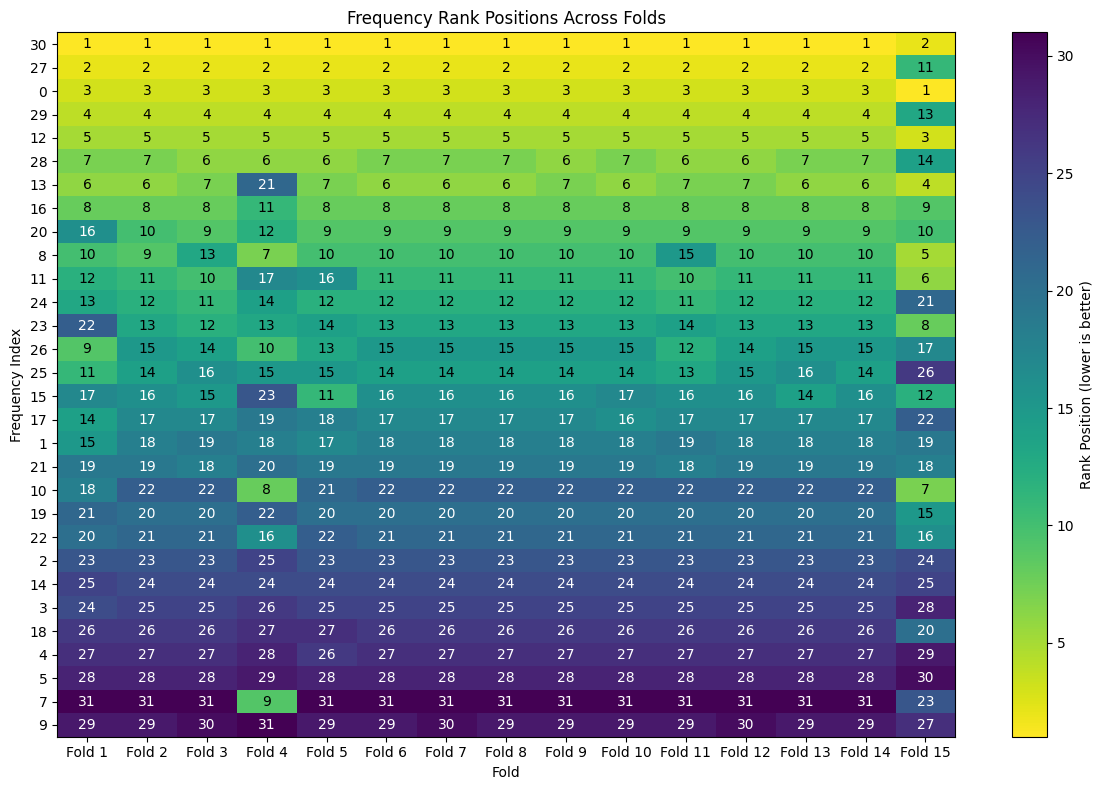

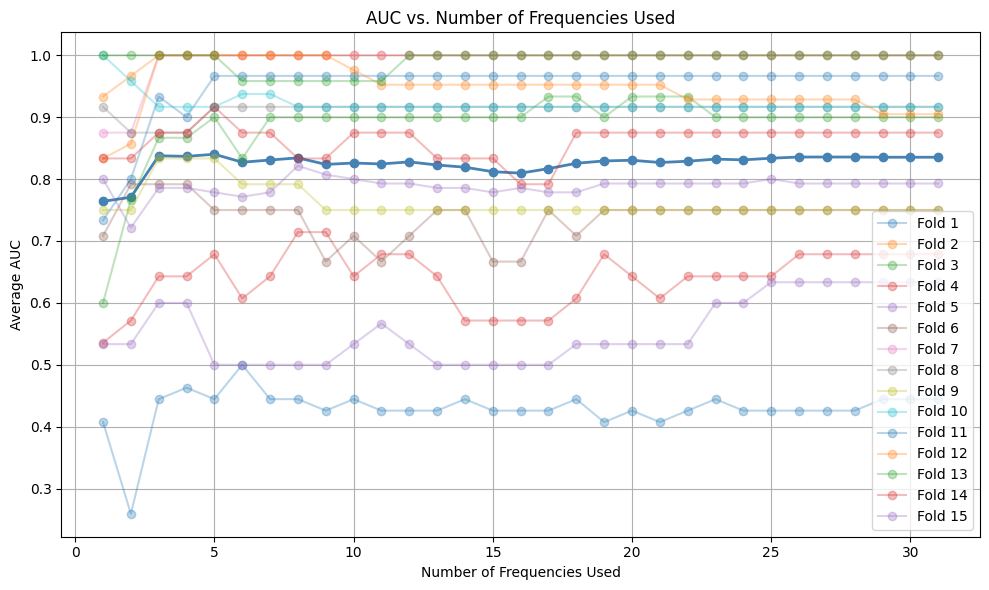

In [14]:
from toolbox.roc_auc import combined_frequency_roc_analysis

aucs, top_freqs, fold_rankings, fold_aucs = combined_frequency_roc_analysis(
    X, Y, Case, max_freqs=31, n_folds=15, random_state=42
)

___

Testing the different heuristically chosen patterns:

- `mask.IIVV_mask("vv_long_across")`
- `mask.IIVV_mask("vv_long_across_extended")`
- `mask.IIVV_mask("vv_medium_across_extended")`
- `mask.IIVV_mask("vv_distance_close_skip_1")`

**2. Long across `vv_long_across`**

config: vv_long_across=array([[26, 31,  1, 22],
       [26, 31,  1, 21],
       [26, 31,  2, 21],
       [26, 31,  2, 22],
       [27, 30,  4, 24],
       [27, 30,  4, 25],
       [27, 30,  5, 24],
       [27, 30,  5, 25],
       [28, 33,  1,  5],
       [28, 33,  1, 10],
       [28, 33,  5,  6],
       [28, 33,  6, 10],
       [29, 32, 16, 20],
       [29, 32, 16, 25],
       [29, 32, 20, 21],
       [29, 32, 21, 25]])


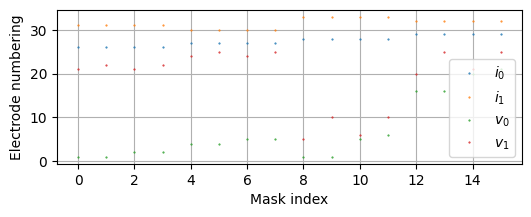

Mask set by IIVV pattern rule.
True: 16 (0.21%)	False: 7712(99.79%)
Performing 15-fold cross-validation with PCA-based frequency ranking and ROC analysis...
Fold 1: 91.7% train / 8.3% test
Fold 1: 91.7% train / 8.3% test
  Training: 166 samples from 88 patients
  Testing:  15 samples from 6 patients
Fold 1 frequency ranking (top 10): [30  0 13 12 29  8 28 16 10 11]
Fold 2: 93.9% train / 6.1% test
Fold 2: 93.9% train / 6.1% test
  Training: 170 samples from 88 patients
  Testing:  11 samples from 6 patients
Fold 2 frequency ranking (top 10): [30  0 13 12 29  8 28 16 11 15]
Fold 3: 93.9% train / 6.1% test
Fold 3: 93.9% train / 6.1% test
  Training: 170 samples from 88 patients
  Testing:  11 samples from 6 patients
Fold 3 frequency ranking (top 10): [30  0 13 12 29 11 16 28 15 10]
Fold 4: 93.9% train / 6.1% test
Fold 4: 93.9% train / 6.1% test
  Training: 170 samples from 88 patients
  Testing:  11 samples from 6 patients
Fold 4 frequency ranking (top 10): [30  0 11 12 29  8 10 28  9 13]

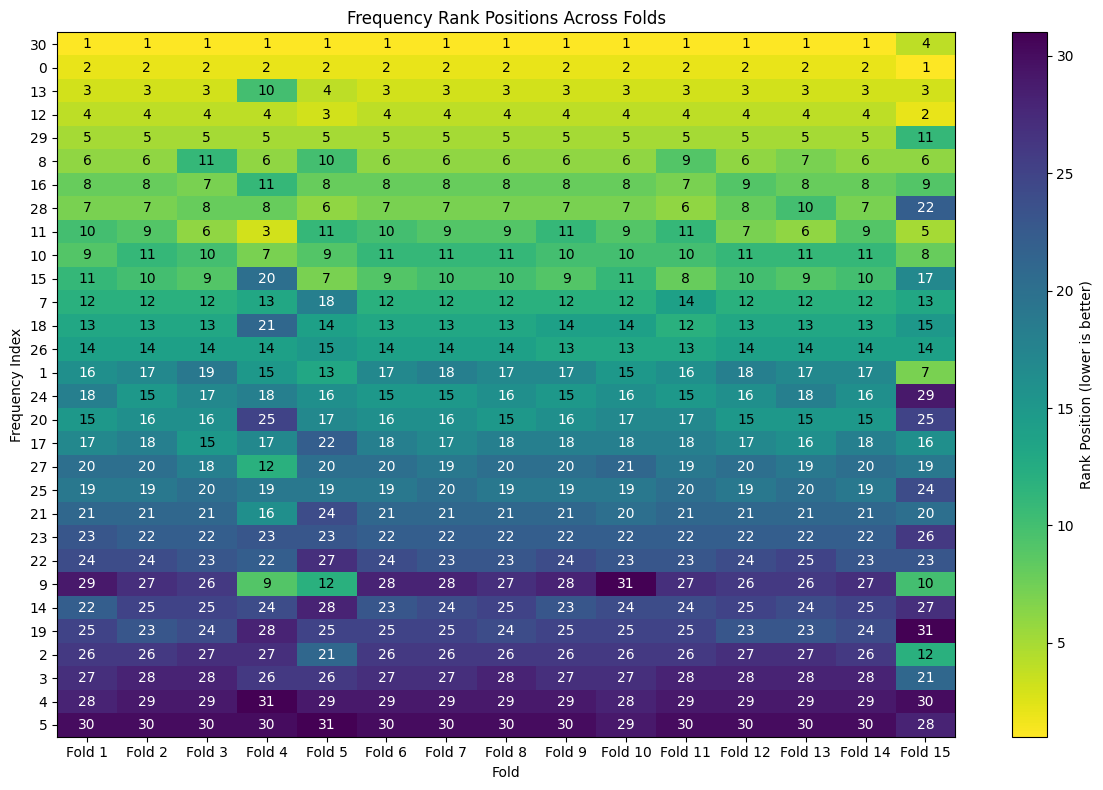

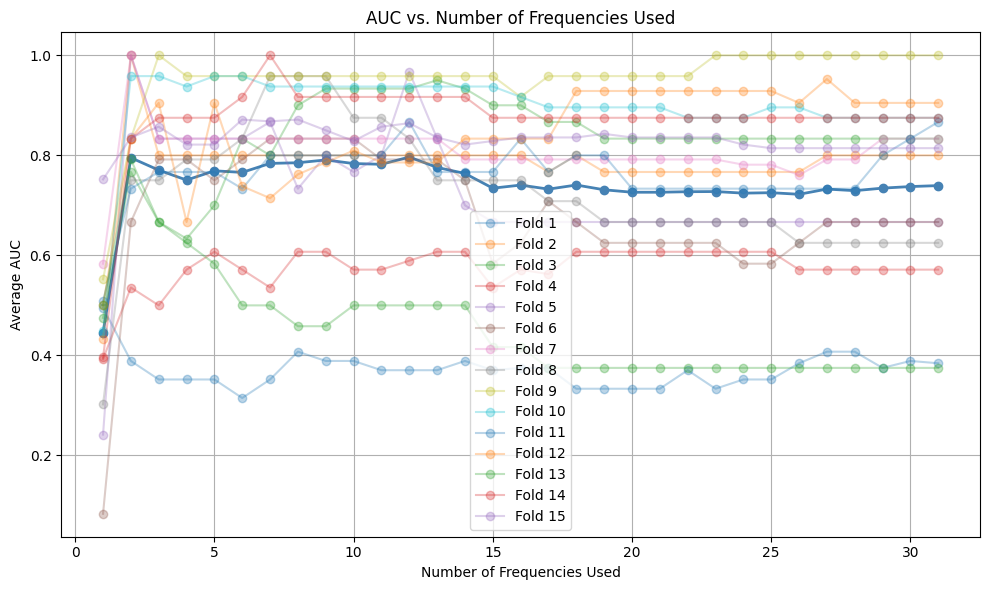

In [15]:
mask.IIVV_mask("vv_long_across")
X_tmp = X[:, :, mask.mask]

aucs, top_freqs, fold_rankings, fold_aucs = combined_frequency_roc_analysis(
    X_tmp, Y, Case, max_freqs=31, n_folds=15, random_state=42
)

**3. Long across extended `vv_long_across_extended`**

config: vv_long_across_extended={'26_31': [1, 2, 3, 21, 22, 23], '27_30': [3, 4, 5, 23, 24, 25], '28_33': [1, 5, 6, 10, 11, 15], '29_32': [11, 15, 16, 20, 21, 25], '30_26': [1, 2, 3, 23, 24, 25], '31_27': [3, 4, 5, 21, 22, 23], '32_28': [5, 10, 11, 15, 16, 21], '33_29': [1, 6, 11, 15, 20, 25]}


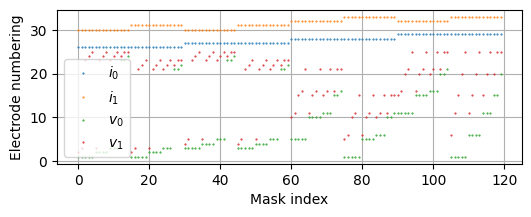

Mask set by IIVV pattern rule.
True: 120 (1.55%)	False: 7608(98.45%)
Performing 15-fold cross-validation with PCA-based frequency ranking and ROC analysis...
Fold 1: 91.7% train / 8.3% test
Fold 1: 91.7% train / 8.3% test
  Training: 166 samples from 88 patients
  Testing:  15 samples from 6 patients
Fold 1 frequency ranking (top 10): [30  0 13 12 29  8 10 16 11 15]
Fold 2: 93.9% train / 6.1% test
Fold 2: 93.9% train / 6.1% test
  Training: 170 samples from 88 patients
  Testing:  11 samples from 6 patients
Fold 2 frequency ranking (top 10): [30  0 13 12 29  8 16 10 11 15]
Fold 3: 93.9% train / 6.1% test
Fold 3: 93.9% train / 6.1% test
  Training: 170 samples from 88 patients
  Testing:  11 samples from 6 patients
Fold 3 frequency ranking (top 10): [30  0 13 12 29  8 16 11 10 15]
Fold 4: 93.9% train / 6.1% test
Fold 4: 93.9% train / 6.1% test
  Training: 170 samples from 88 patients
  Testing:  11 samples from 6 patients
Fold 4 frequency ranking (top 10): [30  0 29 12  8 11 10  9 13 27

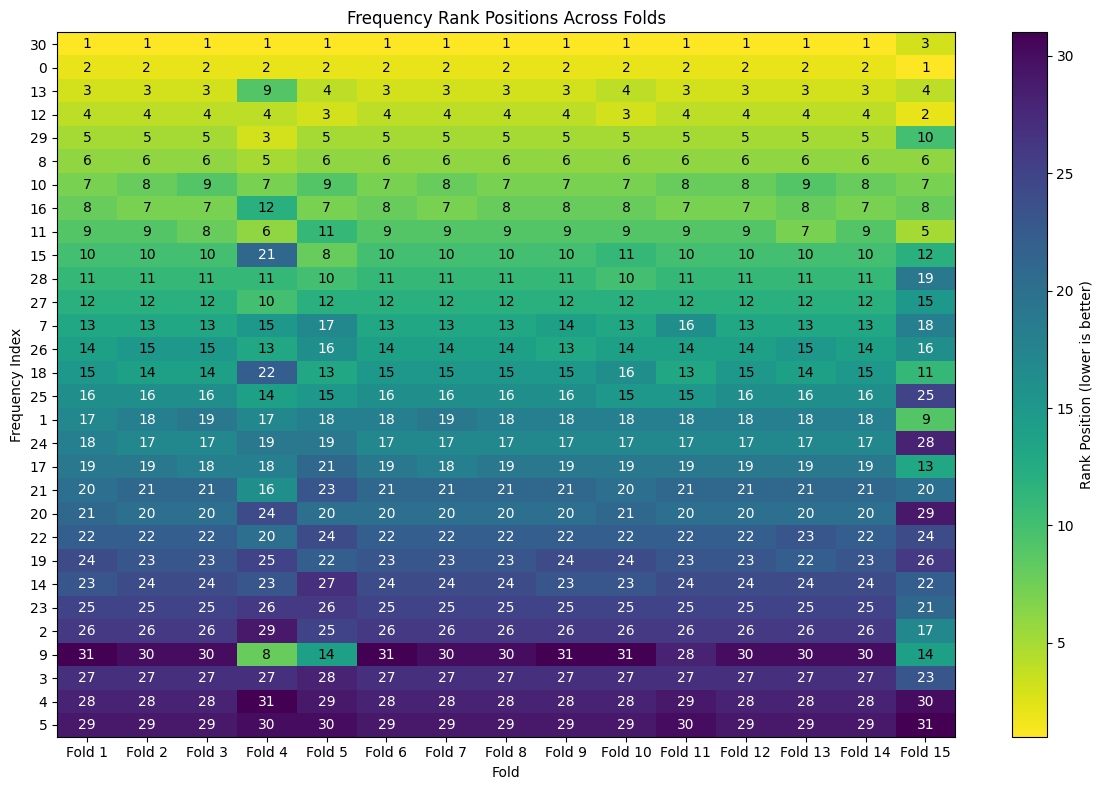

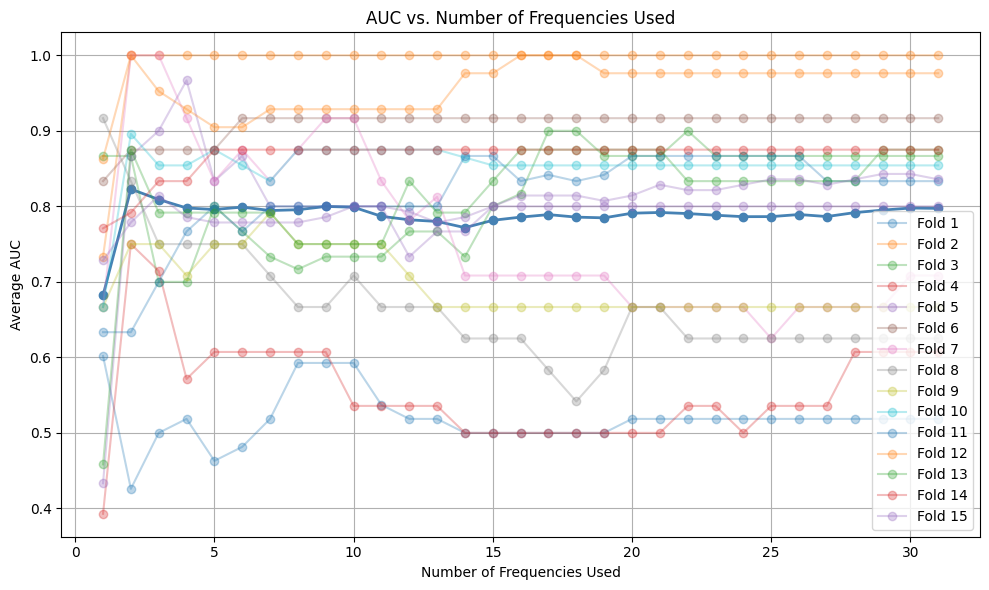

In [16]:
mask.IIVV_mask("vv_long_across_extended")
X_tmp = X[:, :, mask.mask]

aucs, top_freqs, fold_rankings, fold_aucs = combined_frequency_roc_analysis(
    X_tmp, Y, Case, max_freqs=31, n_folds=15, random_state=42
)

**4. Medium across extended `vv_medium_across_extended`**

config: vv_medium_across_extended={'26_31': [6, 7, 8, 16, 17, 18], '27_30': [8, 9, 10, 18, 19, 20], '28_33': [2, 4, 7, 9, 12, 14], '29_32': [12, 14, 17, 19, 22, 24], '30_26': [6, 7, 8, 18, 19, 20], '31_27': [8, 9, 10, 16, 17, 18], '32_28': [12, 14, 17, 19, 22, 24], '33_29': [2, 7, 12, 14, 19, 24]}


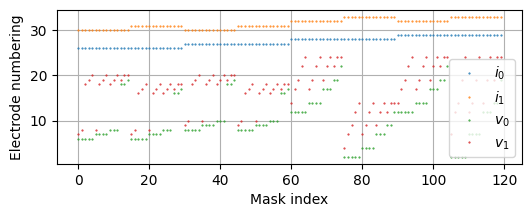

Mask set by IIVV pattern rule.
True: 120 (1.55%)	False: 7608(98.45%)
Performing 15-fold cross-validation with PCA-based frequency ranking and ROC analysis...
Fold 1: 91.7% train / 8.3% test
Fold 1: 91.7% train / 8.3% test
  Training: 166 samples from 88 patients
  Testing:  15 samples from 6 patients
Fold 1 frequency ranking (top 10): [30 27  0 29 12 13 28 16  8 11]
Fold 2: 93.9% train / 6.1% test
Fold 2: 93.9% train / 6.1% test
  Training: 170 samples from 88 patients
  Testing:  11 samples from 6 patients
Fold 2 frequency ranking (top 10): [30 27  0 29 12 13 28 11 16  8]
Fold 3: 93.9% train / 6.1% test
Fold 3: 93.9% train / 6.1% test
  Training: 170 samples from 88 patients
  Testing:  11 samples from 6 patients
Fold 3 frequency ranking (top 10): [30 27  0 29 12 28 13 11 16  8]
Fold 4: 93.9% train / 6.1% test
Fold 4: 93.9% train / 6.1% test
  Training: 170 samples from 88 patients
  Testing:  11 samples from 6 patients
Fold 4 frequency ranking (top 10): [30 27  0 29 12 28 26  8 11 17

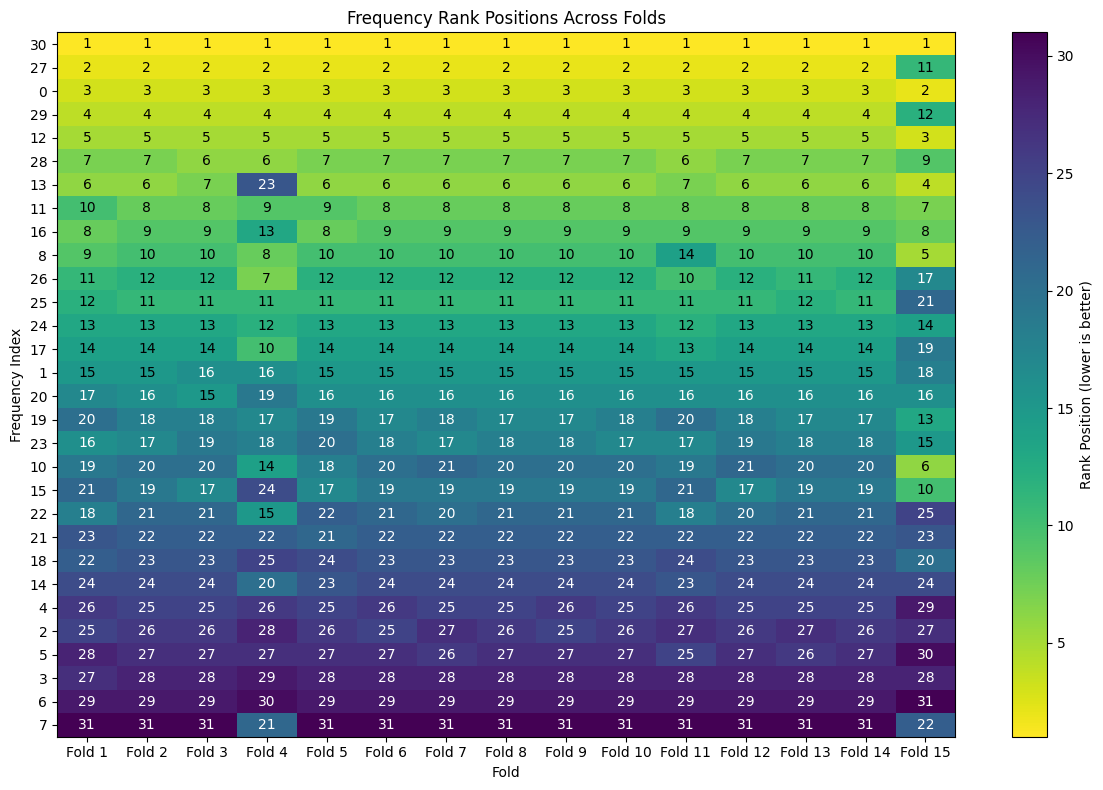

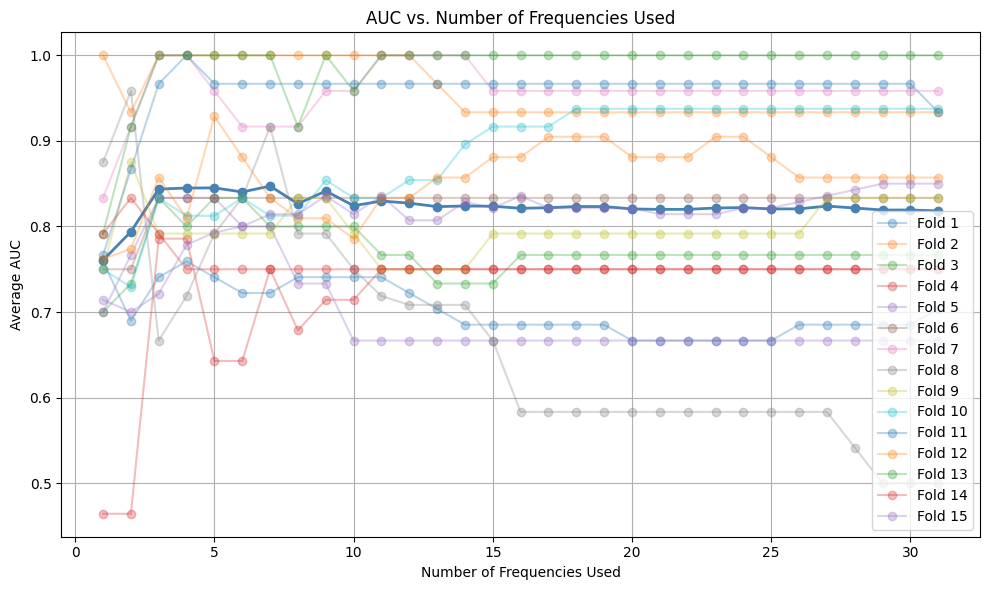

In [17]:
mask.IIVV_mask("vv_medium_across_extended")
X_tmp = X[:, :, mask.mask]

aucs, top_freqs, fold_rankings, fold_aucs = combined_frequency_roc_analysis(
    X_tmp, Y, Case, max_freqs=31, n_folds=15, random_state=42
)

**5. Distance close skip 1 `vv_distance_close_skip_1`**

config: vv_distance_close_skip_1={'26_28': [1, 2, 3, 4, 5, 6, 7, 8, 9, 10], '27_29': [4, 5, 9, 10, 14, 15, 19, 20, 24, 25], '28_30': [4, 5, 9, 10, 14, 15, 19, 20, 24, 25], '29_31': [16, 17, 18, 19, 20, 21, 22, 23, 24, 25], '30_32': [16, 17, 18, 19, 20, 21, 22, 23, 24, 25], '31_33': [1, 2, 6, 7, 11, 12, 16, 17, 21, 22], '32_26': [1, 2, 6, 7, 11, 12, 16, 17, 21, 22], '33_27': [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]}


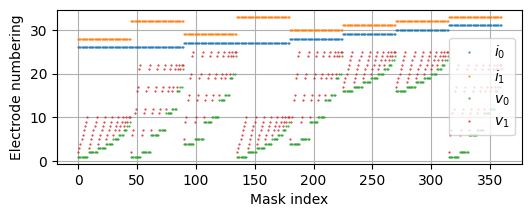

Mask set by IIVV pattern rule.
True: 360 (4.66%)	False: 7368(95.34%)
Performing 15-fold cross-validation with PCA-based frequency ranking and ROC analysis...
Fold 1: 91.7% train / 8.3% test
Fold 1: 91.7% train / 8.3% test
  Training: 166 samples from 88 patients
  Testing:  15 samples from 6 patients
Fold 1 frequency ranking (top 10): [30  0 29 12 13  8 10 28 16 11]
Fold 2: 93.9% train / 6.1% test
Fold 2: 93.9% train / 6.1% test
  Training: 170 samples from 88 patients
  Testing:  11 samples from 6 patients
Fold 2 frequency ranking (top 10): [30  0 12 29 13  8 27 16 28 10]
Fold 3: 93.9% train / 6.1% test
Fold 3: 93.9% train / 6.1% test
  Training: 170 samples from 88 patients
  Testing:  11 samples from 6 patients
Fold 3 frequency ranking (top 10): [30  0 29 27 12 13 28 16 15 20]
Fold 4: 93.9% train / 6.1% test
Fold 4: 93.9% train / 6.1% test
  Training: 170 samples from 88 patients
  Testing:  11 samples from 6 patients
Fold 4 frequency ranking (top 10): [30  0 29 27 12  8 28 10 13 11

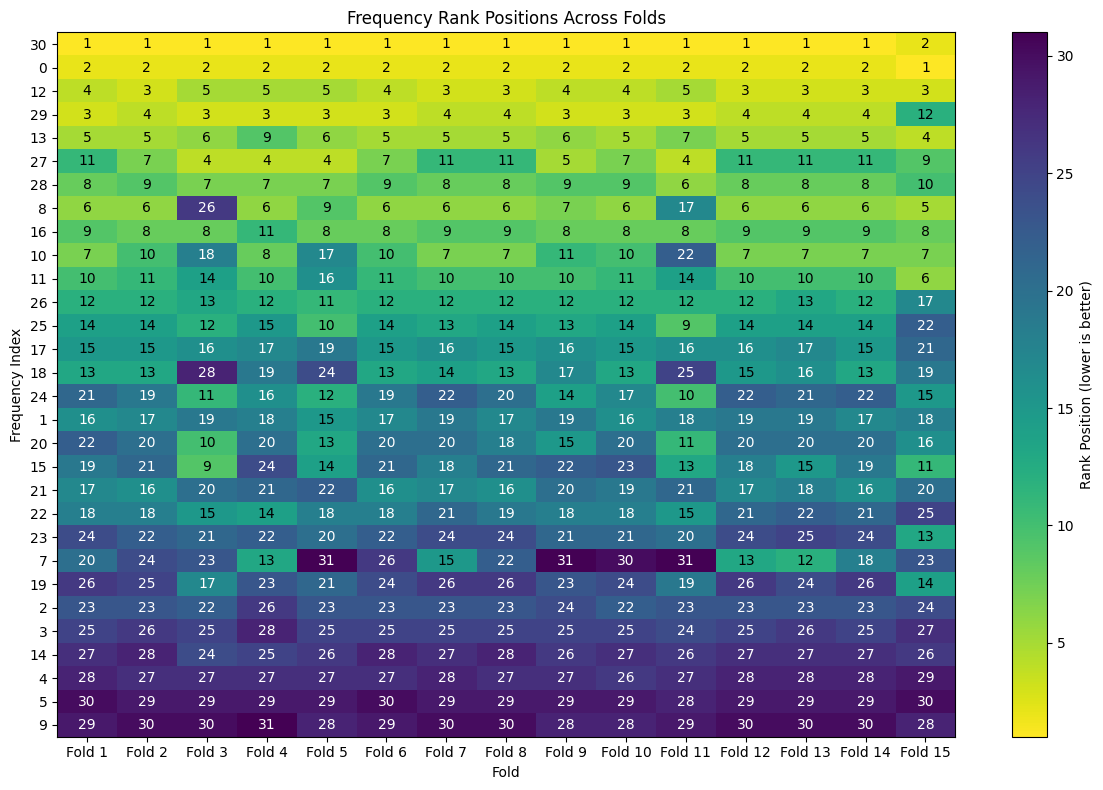

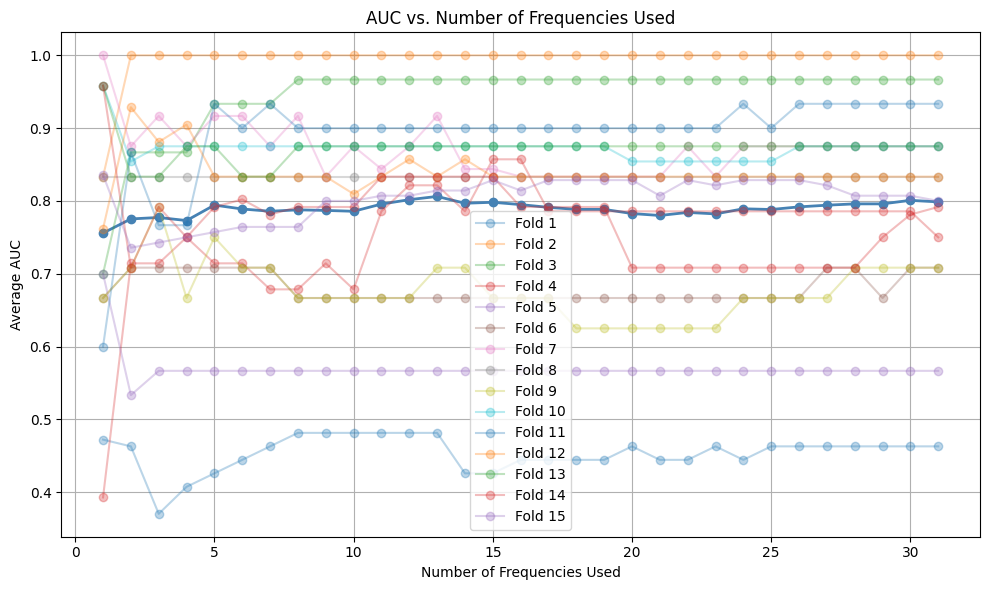

In [18]:
mask.IIVV_mask("vv_distance_close_skip_1")
X_tmp = X[:, :, mask.mask]

aucs, top_freqs, fold_rankings, fold_aucs = combined_frequency_roc_analysis(
    X_tmp, Y, Case, max_freqs=31, n_folds=15, random_state=42
)

___